In [18]:
from pathlib import Path
import pandas as pd
import numpy as np
import librosa
import librosa.display
import matplotlib.pyplot as plt
import IPython.display as ipd

DATA_DIR = Path("../data/ravdess")
assert DATA_DIR.exists(), f"Folder not found: {DATA_DIR.resolve()   }"


In [19]:
EMOTIONS = {
    "01": "neutral", "02": "calm", "03": "happy", "04": "sad",
    "05": "angry", "06": "fearful", "07": "disgust", "08": "surprised",
}

rows = []
for f in DATA_DIR.rglob("*.wav"):
    parts = f.stem.split("-")
    if len(parts) != 7:
        continue  # skip anything that isn't a RAVDESS file
    actor = int(parts[6])
    rows.append({
        "path": str(f),
        "emotion": EMOTIONS[parts[2]],
        "intensity": "normal" if parts[3] == "01" else "strong",
        "statement": int(parts[4]),
        "repetition": int(parts[5]),
        "actor": actor,
        "gender": "male" if actor % 2 == 1 else "female",
    })

df = pd.DataFrame(rows).sort_values(["actor", "emotion"]).reset_index(drop=True)
print("Shape:", df.shape)
df.head()

Shape: (1440, 7)


,path,emotion,intensity,statement,repetition,actor,gender
0,..\data\ravdess\Actor_01\03-01-05-01-01-01-01.wav,angry,normal,1,1,1,male
1,..\data\ravdess\Actor_01\03-01-05-01-01-02-01.wav,angry,normal,1,2,1,male
2,..\data\ravdess\Actor_01\03-01-05-01-02-01-01.wav,angry,normal,2,1,1,male
3,..\data\ravdess\Actor_01\03-01-05-01-02-02-01.wav,angry,normal,2,2,1,male
4,..\data\ravdess\Actor_01\03-01-05-02-01-01-01.wav,angry,strong,1,1,1,male


In [20]:
print("Files:", len(df), "| Actors:", df["actor"].nunique())
print("\nFiles per emotion:")
print(df["emotion"].value_counts())  # neutral has half as many (no 'strong' version)
print("\nFiles per actor (should all be 60):")
print(df["actor"].value_counts().sort_index().unique())

Files: 1440 | Actors: 24

Files per emotion:
emotion
angry        192
calm         192
disgust      192
fearful      192
happy        192
sad          192
surprised    192
neutral       96
Name: count, dtype: int64

Files per actor (should all be 60):
[60]


In [24]:
Path("../data").mkdir(exist_ok=True)
df.to_csv("../data/metadata.csv", index=False)
print("Saved data/metadata.csv")

Saved data/metadata.csv


In [25]:
sample = df.iloc[0]
y, sr = librosa.load(sample["path"], sr=None)  # sr=None keeps the original sampling rate
print(f"Emotion: {sample['emotion']} | Sampling rate: {sr} Hz | Duration: {len(y)/sr:.2f} s | Samples: {len(y)}")
ipd.Audio(y, rate=sr)

Emotion: angry | Sampling rate: 48000 Hz | Duration: 3.87 s | Samples: 185786


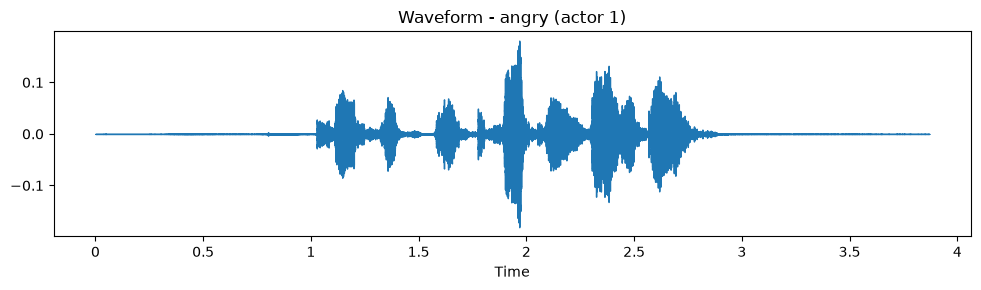

In [26]:
plt.figure(figsize=(10, 3))
librosa.display.waveshow(y, sr=sr)
plt.title(f"Waveform - {sample['emotion']} (actor {sample['actor']})")
plt.tight_layout()
plt.show()

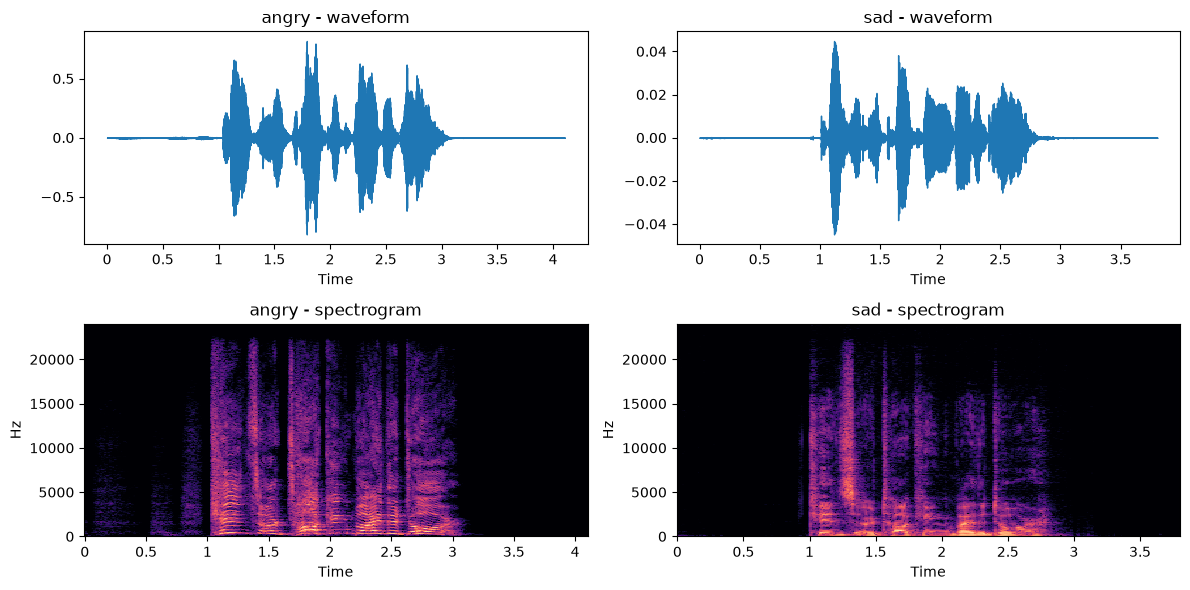

Angry:


Sad:


In [27]:
actor_id = 1
pair = {}
for emo in ["angry", "sad"]:
    row = df[(df.actor == actor_id) & (df.emotion == emo) &
             (df.intensity == "strong") & (df.statement == 1) & (df.repetition == 1)].iloc[0]
    pair[emo], _ = librosa.load(row["path"], sr=sr)

fig, axes = plt.subplots(2, 2, figsize=(12, 6))
for i, (emo, sig) in enumerate(pair.items()):
    librosa.display.waveshow(sig, sr=sr, ax=axes[0, i])
    axes[0, i].set_title(f"{emo} - waveform")
    S = librosa.amplitude_to_db(np.abs(librosa.stft(sig)), ref=np.max)
    librosa.display.specshow(S, sr=sr, x_axis="time", y_axis="hz", ax=axes[1, i])
    axes[1, i].set_title(f"{emo} - spectrogram")
plt.tight_layout()
plt.show()

# Listen to both:
print("Angry:")
ipd.display(ipd.Audio(pair["angry"], rate=sr))
print("Sad:")
ipd.display(ipd.Audio(pair["sad"], rate=sr))